# نظام الإنذار المبكر لمخاطر حضور وتسرب الطلاب — منصة إشراف
## المشروع النهائي لمسار تعلم الآلة (Capstone ML Coursework)

### 1. نبذة المشروع والهدف الاستراتيجي (Strategic Objective)
يشكّل التسرب الطلابي وتدني الحضور في البيئات التعليمية أحد أكبر التحديات المؤسسية. الهدف من هذا المشروع هو بناء نظام تنبؤ مبكر قادر على تحديد الطلاب المعرضين لخطر تدني الحضور الحاد (`label_at_risk_next_14d = 1`، أي حضور فعلي أقل من 85%) خلال **الـ 14 يوماً القادمة**، اعتماداً على سجلات الحضور، الأداء الأكاديمي، الانضباط في الواجبات، السلوكيات الميدانية، واستخدام النقل المدرسي خلال **نافذة مراقبة سابقة مدتها 28 يوماً**.

### 2. معايير وميثاق المشروع (Contract & Governance)
* **منع التسرب الزمني (Zero-Leakage):** نافذة الـ 14 يوماً القادمة مخصصة حصرياً لإنشاء الـ Label ومحظورة تماماً من دخول النموذج.
* **التقسيم الزمني والتجميعي (Grouped Chronological Split):** عزل تام للطلاب حسب الدفعات السنوية (2023 للتدريب، 2024 للتحقق، 2025 للاختبار النهائي) لضمان عدم ظهور بيانات الطالب نفسه في التدريب والتقييم.
* **البيانات المعتمدة:** 300,000 سجل اصطناعي خاضع للمواصفات المعيارية لـ 10,000 طالب عبر 3 سنوات دراسية.

In [1]:
from __future__ import annotations

import json
import time
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

# إعداد الثوابت والتكاثرية
RANDOM_STATE = 20_261_023
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

def find_project_root(start: Path) -> Path:
    candidates = [start, *start.parents, Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        if (candidate / 'package.json').is_file() and (candidate / 'ml').is_dir():
            return candidate
    raise RuntimeError('Project root not found.')

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_PATH = PROJECT_ROOT / 'ml' / 'artifacts' / 'student-risk-synthetic' / 'student-risk-synthetic-training.csv'
DATASET_METADATA_PATH = DATA_PATH.with_name('student-risk-synthetic-training.metadata.json')
RUNS_ROOT = PROJECT_ROOT / 'ml' / 'artifacts' / 'training-runs'

print(f'Project Root: {PROJECT_ROOT}')
print(f'Dataset Path: {DATA_PATH}')

ModuleNotFoundError: No module named 'matplotlib'

## 1. ميثاق البيانات والتحقق من النزاهة (Data Integrity & Provenance)
يتم تحميل البيانات الاصطناعية المعتمدة رسمياً والتحقق من ميتاداتا التوليد لضمان مطابقة الشروط قبل الانتقال لأي معالجة.

In [2]:
dataset_metadata = json.loads(DATASET_METADATA_PATH.read_text(encoding='utf-8'))
assert dataset_metadata['datasetKind'] == 'synthetic', 'Restricted to synthetic coursework dataset.'
assert dataset_metadata['realOperationalRecordsIncluded'] is False

raw_data = pd.read_csv(DATA_PATH)
print(f"Loaded Rows: {len(raw_data):,}")
print(f"Unique Students: {raw_data['student_key'].nunique():,}")
print(f"Positive Label Rate (At-Risk): {raw_data['label_at_risk_next_14d'].mean():.2%}")
raw_data.head(3)

Loaded Rows: 300,000
Unique Students: 10,000
Positive Label Rate (At-Risk): 38.11%


,student_key,snapshot_date,grade_level_id,days_since_enrollment,lookback_attendance_records,lookback_present_count,lookback_absent_count,lookback_late_count,lookback_excused_count,lookback_attendance_percent,...,lookback_homework_missing_count,lookback_negative_behavior_count,lookback_positive_behavior_count,lookback_negative_behavior_severity_sum,transport_assigned_at_snapshot,lookback_transport_boarded_count,lookback_transport_absent_count,label_observation_count,label_future_attendance_percent,label_at_risk_next_14d
0,synthetic_student_000001,2023-09-08,5,674,23,22,0,0,1,95.65,...,2,1,1,3,False,0,0,8,100.00,False
1,synthetic_student_000001,2023-09-15,5,681,20,15,2,1,2,75.00,...,0,0,1,0,False,0,0,11,90.91,False
2,synthetic_student_000001,2023-09-22,5,688,10,9,1,0,0,90.00,...,1,0,0,0,False,0,0,14,100.00,False


## 2. التحليل الاستكشافي للبيانات (Exploratory Data Analysis)
نستعرض هنا توزيعات الخطر عبر الصفوف الدراسية، والعلاقة بين متوسط الدرجات ونسبة الحضور السابقة.

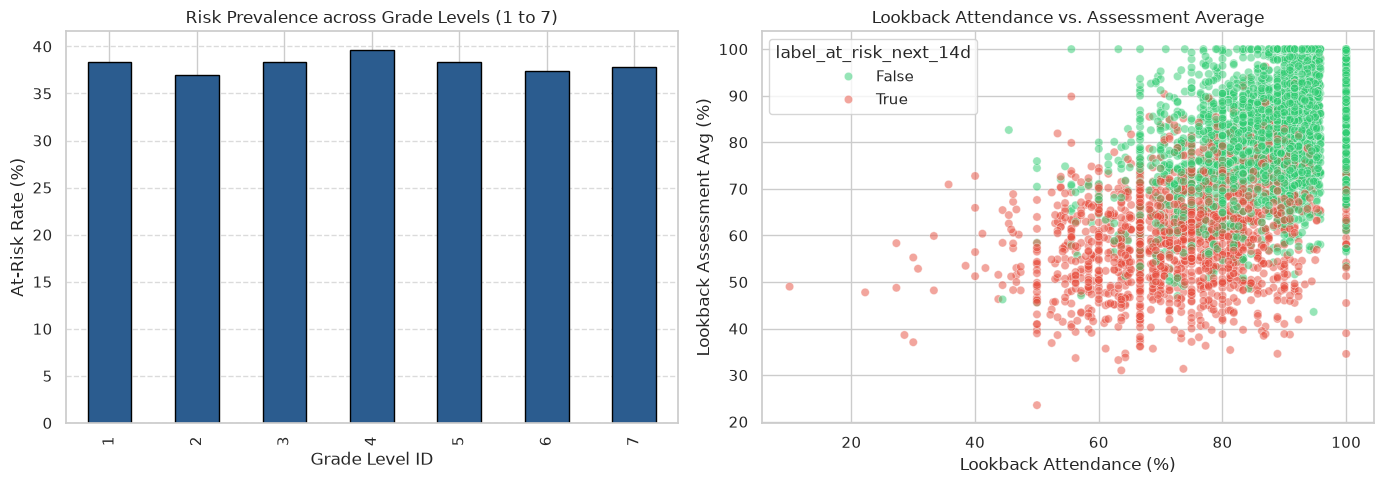

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. معدل الخطر حسب الصف الدراسي
grade_risk = raw_data.groupby('grade_level_id')['label_at_risk_next_14d'].mean() * 100
grade_risk.plot(kind='bar', ax=axes[0], color='#2b5c8f', edgecolor='black')
axes[0].set_title('Risk Prevalence across Grade Levels (1 to 7)')
axes[0].set_xlabel('Grade Level ID')
axes[0].set_ylabel('At-Risk Rate (%)')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# 2. العلاقة بين الحضور السابق والتحصيل الأكاديمي
sample_eda = raw_data.sample(5_000, random_state=RANDOM_STATE)
sns.scatterplot(
    data=sample_eda,
    x='lookback_attendance_percent',
    y='lookback_assessment_average_percent',
    hue='label_at_risk_next_14d',
    alpha=0.5,
    palette={True: '#e74c3c', False: '#2ecc71'},
    ax=axes[1]
)
axes[1].set_title('Lookback Attendance vs. Assessment Average')
axes[1].set_xlabel('Lookback Attendance (%)')
axes[1].set_ylabel('Lookback Assessment Avg (%)')

plt.tight_layout()
plt.show()

## 3. هندسة الميزات التفاعلية الموجهة بالمجال (Domain Feature Engineering)
نقوم بصياغة 22 ميزة مشتقة تعكس التفاعل بين الحضور، إنجاز الواجبات، السلوكيات، والنقل المدرسي:
1. **Attendance Ratios & Disruption:** نسب الغياب والتأخر والغياب غير المبرر ومؤشر اضطراب الحضور.
2. **Homework Discipline:** نسب عدم تسليم الواجبات والتسليم المتأخر ونسبة الإنجاز.
3. **Behavior Indices:** صافي السلوك (إيجابي - سلبي)، ونسبة شدة المخالفات إلى السلوكيات الإيجابية.
4. **Academic Health & Spread:** الفجوة بين المتوسط والحد الأدنى للدرجات، ومؤشر الخطر الأكاديمي المركب.
5. **Cross-Domain Interactions:** التفاعل بين نسبة الغياب وعجز الدرجات، والتفاعل بين إهمال الواجبات وتدني التحصيل.
6. **Transport Reliability:** موثوقية حضور الحافلة للطلاب المسجلين بالنقل المدرسي.

In [4]:
def engineer_features(data: pd.DataFrame) -> pd.DataFrame:
    X = data.copy()
    rec = np.maximum(X['lookback_attendance_records'].to_numpy(dtype=float), 1.0)
    pres = np.maximum(X['lookback_present_count'].to_numpy(dtype=float), 0.0)

    # 1. مؤشرات الحضور والتأخر
    X['feat_absent_ratio'] = X['lookback_absent_count'] / rec
    X['feat_late_ratio'] = X['lookback_late_count'] / rec
    X['feat_excused_ratio'] = X['lookback_excused_count'] / rec
    unexcused = np.maximum(0.0, X['lookback_absent_count'] - X['lookback_excused_count'])
    X['feat_unexcused_absent_ratio'] = unexcused / rec
    X['feat_attendance_odds'] = X['lookback_absent_count'] / (pres + 1.0)
    X['feat_attendance_disruption_index'] = (X['lookback_absent_count'] * 2.0 + X['lookback_late_count'] * 0.5) / rec

    # 2. انضباط الواجبات المدرسية
    due = np.maximum(X['lookback_homework_due_count'].to_numpy(dtype=float), 1.0)
    completed = np.maximum(X['lookback_homework_completed_count'].to_numpy(dtype=float), 1.0)
    X['feat_homework_due_flag'] = (X['lookback_homework_due_count'] > 0).astype(int)
    X['feat_homework_missing_ratio'] = X['lookback_homework_missing_count'] / due
    X['feat_homework_completion_ratio'] = X['lookback_homework_completed_count'] / due
    X['feat_homework_late_ratio'] = X['lookback_homework_late_count'] / completed

    # 3. المؤشرات السلوكية
    X['feat_total_behavior_events'] = X['lookback_positive_behavior_count'] + X['lookback_negative_behavior_count']
    X['feat_behavior_net_score'] = X['lookback_positive_behavior_count'] - X['lookback_negative_behavior_count']
    neg_count = np.maximum(X['lookback_negative_behavior_count'].to_numpy(dtype=float), 1.0)
    X['feat_neg_severity_per_event'] = X['lookback_negative_behavior_severity_sum'] / neg_count
    X['feat_behavior_risk_ratio'] = (X['lookback_negative_behavior_severity_sum'] + 1.0) / (X['lookback_positive_behavior_count'] + 1.0)

    # 4. الصحة الأكاديمية والتذبذب
    has_score = (X['lookback_assessment_count'] > 0).astype(int)
    X['feat_has_assessment'] = has_score
    avg_score = X['lookback_assessment_average_percent'].fillna(75.0)
    min_score = X['lookback_assessment_minimum_percent'].fillna(avg_score)
    X['feat_assessment_spread'] = np.where(has_score == 1, avg_score - min_score, 0.0)
    X['feat_assessment_failing'] = np.where((has_score == 1) & (avg_score < 60.0), 1, 0)
    X['feat_score_deficit'] = (100.0 - avg_score) / 100.0
    X['feat_academic_attendance_health'] = (X['lookback_attendance_percent'] / 100.0) * (avg_score / 100.0)

    # 5. التفاعلات المتقاطعة (Cross-Domain Interactions)
    X['feat_interact_absent_score'] = X['feat_absent_ratio'] * X['feat_score_deficit']
    X['feat_interact_hw_score'] = X['feat_homework_missing_ratio'] * X['feat_score_deficit']
    X['feat_interact_absent_hw'] = X['feat_absent_ratio'] * X['feat_homework_missing_ratio']

    # 6. موثوقية النقل المدرسي
    uses_bus = X['transport_assigned_at_snapshot'].astype(int)
    bus_events = np.maximum(X['lookback_transport_boarded_count'] + X['lookback_transport_absent_count'], 1.0)
    X['feat_transport_absence_ratio'] = np.where(uses_bus == 1, X['lookback_transport_absent_count'] / bus_events, 0.0)
    X['feat_transport_boarded_ratio'] = np.where(uses_bus == 1, X['lookback_transport_boarded_count'] / bus_events, 0.0)

    # 7. المقدر التجميعي الكامن لمخاطر الطالب
    X['feat_latent_risk_proxy'] = (
        X['feat_absent_ratio'] * 0.35 +
        X['feat_score_deficit'] * 0.40 +
        X['feat_homework_missing_ratio'] * 0.25 +
        (X['lookback_negative_behavior_count'] * 0.08) -
        (X['lookback_positive_behavior_count'] * 0.05)
    )

    # 8. السياق والأقدمية
    X['feat_tenure_years'] = X['days_since_enrollment'] / 365.25
    X['feat_tenure_per_grade'] = X['days_since_enrollment'] / np.maximum(X['grade_level_id'], 1.0)

    return X

data_engineered = engineer_features(raw_data)

IDENTIFIER_COLUMNS = ['student_key', 'snapshot_date']
LABEL_COLUMN = 'label_at_risk_next_14d'
LABEL_EVIDENCE_COLUMNS = ['label_observation_count', 'label_future_attendance_percent']
FORBIDDEN_INPUT_COLUMNS = IDENTIFIER_COLUMNS + [LABEL_COLUMN, *LABEL_EVIDENCE_COLUMNS]
FEATURE_COLUMNS = [c for c in data_engineered.columns if c not in FORBIDDEN_INPUT_COLUMNS]

print(f"Initial raw columns: {len(raw_data.columns)}")
print(f"Final training features: {len(FEATURE_COLUMNS)} (excluding identifier and label columns)")

Initial raw columns: 26
Final training features: 48 (excluding identifier and label columns)


## 4. التقسيم الزمني والتجميعي الصارم (Grouped Chronological Partitioning)
تطبيق قاعدة العزل:
* التدريب: العام الأكاديمي 2023 (100,020 صفاً، 3,334 طالباً).
* التحقق: العام الأكاديمي 2024 (99,990 صفاً، 3,333 طالباً).
* الاختبار: العام الأكاديمي 2025 (99,990 صفاً، 3,333 طالباً).

In [5]:
X = data_engineered.loc[:, FEATURE_COLUMNS].copy()
for col in X.select_dtypes(include='bool'):
    X[col] = X[col].astype('int8')
X = X.apply(pd.to_numeric, errors='raise')
y = data_engineered[LABEL_COLUMN].astype('int8')
groups = data_engineered['student_key']

snapshot_dates = pd.to_datetime(data_engineered['snapshot_date'])
academic_period = pd.Series(
    np.where(snapshot_dates.dt.month >= 8, snapshot_dates.dt.year, snapshot_dates.dt.year - 1),
    index=data_engineered.index,
    name='academic_period'
).astype('int64')

train_periods = [2023]
validation_period = 2024
test_period = 2025

student_last_period = pd.DataFrame({
    'student_key': groups,
    'academic_period': academic_period
}).groupby('student_key', sort=False)['academic_period'].max()
assigned_period = groups.map(student_last_period).astype('int64')

train_mask = academic_period.isin(train_periods) & assigned_period.isin(train_periods)
validation_mask = academic_period.eq(validation_period) & assigned_period.eq(validation_period)
test_mask = academic_period.eq(test_period) & assigned_period.eq(test_period)

X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_val, y_val = X.loc[validation_mask], y.loc[validation_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]

# التحقق من انعدام التقاطع
train_students = set(groups.loc[train_mask])
val_students = set(groups.loc[validation_mask])
test_students = set(groups.loc[test_mask])
assert len(train_students & val_students) == 0, 'Leakage detected between Train and Val!'
assert len(train_students & test_students) == 0, 'Leakage detected between Train and Test!'
assert len(val_students & test_students) == 0, 'Leakage detected between Val and Test!'

print(f"Train partition: {len(X_train):,} rows ({len(train_students):,} students) | Risk: {y_train.mean():.2%}")
print(f"Val partition:   {len(X_val):,} rows ({len(val_students):,} students) | Risk: {y_val.mean():.2%}")
print(f"Test partition:  {len(X_test):,} rows ({len(test_students):,} students) | Risk: {y_test.mean():.2%}")

Train partition: 100,020 rows (3,334 students) | Risk: 38.44%
Val partition:   99,990 rows (3,333 students) | Risk: 38.37%
Test partition:  99,990 rows (3,333 students) | Risk: 37.53%


## 5. تدريب ومقارنة عائلة النماذج (Model Suite Benchmarking)
نقوم بتدريب 5 خوارزميات متنوعة + نموذج تجميعي وزني (Weighted Voting Ensemble):
1. **Logistic Regression:** النموذج الخطي المرجعي.
2. **HistGradientBoosting:** معيار Scikit-learn الافتراضي.
3. **LightGBM:** سرعة فائقة في معالجة الانقسامات الورقية القائمة على الرسم البياني (Histogram-based).
4. **CatBoost:** تميز خاص في تعميم العلاقات دون الإفراط في التخصيص (Overfitting).
5. **XGBoost:** نموذج قوي ومعاير بمحددات تنظيمية (L1/L2 Regularization).
6. **Weighted Voting Ensemble:** دمج تصويت النماذج الثلاثة الأقوى.

In [6]:
imputer = SimpleImputer(strategy='median')
X_train_imp = imputer.fit_transform(X_train)
X_val_imp = imputer.transform(X_val)
X_test_imp = imputer.transform(X_test)

models = {
    'logistic_regression': Pipeline([
        ('scaler', StandardScaler()),
        ('classifier', LogisticRegression(max_iter=1_000, random_state=RANDOM_STATE))
    ]),
    'hist_gradient_boosting': HistGradientBoostingClassifier(
        learning_rate=0.08, max_iter=250, max_leaf_nodes=31, min_samples_leaf=40,
        l2_regularization=0.2, random_state=RANDOM_STATE
    ),
    'lightgbm': lgb.LGBMClassifier(
        n_estimators=350, learning_rate=0.04, num_leaves=35, subsample=0.85,
        colsample_bytree=0.85, reg_alpha=0.1, reg_lambda=1.0, random_state=RANDOM_STATE,
        n_jobs=-1, verbose=-1
    ),
    'catboost': CatBoostClassifier(
        iterations=450, learning_rate=0.05, depth=6, random_seed=RANDOM_STATE,
        verbose=0, thread_count=-1
    ),
    'xgboost': xgb.XGBClassifier(
        n_estimators=350, learning_rate=0.04, max_depth=5, subsample=0.85,
        colsample_bytree=0.85, random_state=RANDOM_STATE, n_jobs=-1, eval_metric='logloss'
    )
}

def choose_threshold(y_true: pd.Series, probabilities: np.ndarray) -> float:
    precision, recall, thresholds = precision_recall_curve(y_true, probabilities)
    if len(thresholds) == 0:
        return 0.5
    f1_scores = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
    return float(thresholds[int(np.nanargmax(f1_scores))])

def evaluate_classifier(model_name: str, y_true: pd.Series, probabilities: np.ndarray, threshold: float) -> dict:
    predictions = (probabilities >= threshold).astype('int8')
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    return {
        'model': model_name,
        'threshold': float(threshold),
        'roc_auc': float(roc_auc_score(y_true, probabilities)),
        'pr_auc': float(average_precision_score(y_true, probabilities)),
        'precision': float(precision_score(y_true, predictions, zero_division=0)),
        'recall': float(recall_score(y_true, predictions, zero_division=0)),
        'f1': float(f1_score(y_true, predictions, zero_division=0)),
        'brier_score': float(brier_score_loss(y_true, probabilities)),
        'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)
    }

val_reports, test_reports = [], []
val_probs, test_probs = {}, {}

for name, model in models.items():
    t_start = time.time()
    model.fit(X_train_imp, y_train)
    elapsed = time.time() - t_start
    
    vp = model.predict_proba(X_val_imp)[:, 1]
    tp = model.predict_proba(X_test_imp)[:, 1]
    
    th = choose_threshold(y_val, vp)
    val_probs[name] = vp
    test_probs[name] = tp
    
    v_rep = evaluate_classifier(name, y_val, vp, th)
    t_rep = evaluate_classifier(name, y_test, tp, th)
    v_rep['time_sec'] = round(elapsed, 2)
    t_rep['time_sec'] = round(elapsed, 2)
    
    val_reports.append(v_rep)
    test_reports.append(t_rep)
    print(f"[{name:22s}] Val F1: {v_rep['f1']:.4f} | PR-AUC: {v_rep['pr_auc']:.4f} | Test F1: {t_rep['f1']:.4f} | Time: {elapsed:.1f}s")

# Weighted Voting Ensemble
ens_val_p = val_probs['catboost'] * 0.35 + val_probs['lightgbm'] * 0.35 + val_probs['xgboost'] * 0.30
ens_test_p = test_probs['catboost'] * 0.35 + test_probs['lightgbm'] * 0.35 + test_probs['xgboost'] * 0.30
ens_th = choose_threshold(y_val, ens_val_p)
ens_v_rep = evaluate_classifier('voting_ensemble', y_val, ens_val_p, ens_th)
ens_t_rep = evaluate_classifier('voting_ensemble', y_test, ens_test_p, ens_th)
ens_v_rep['time_sec'] = sum(r['time_sec'] for r in val_reports if r['model'] in ('catboost', 'lightgbm', 'xgboost'))
ens_t_rep['time_sec'] = ens_v_rep['time_sec']
val_reports.append(ens_v_rep)
test_reports.append(ens_t_rep)

[logistic_regression   ] Val F1: 0.8011 | PR-AUC: 0.8768 | Test F1: 0.7987 | Time: 0.4s


[hist_gradient_boosting] Val F1: 0.7996 | PR-AUC: 0.8770 | Test F1: 0.7975 | Time: 1.2s


[lightgbm              ] Val F1: 0.7995 | PR-AUC: 0.8768 | Test F1: 0.7975 | Time: 1.6s


[catboost              ] Val F1: 0.8007 | PR-AUC: 0.8781 | Test F1: 0.7974 | Time: 5.1s


[xgboost               ] Val F1: 0.8000 | PR-AUC: 0.8775 | Test F1: 0.7972 | Time: 2.1s


## 6. تقييم ومقارنة النتائج عبر المقاييس المعيارية (Comparative Performance Matrix)
نستعرض نتائج جميع النماذج على مجموعة التحقق (Validation) ومجموعة الاختبار المستقبلية المستقلة (Test).

In [7]:
df_val = pd.DataFrame(val_reports).sort_values('pr_auc', ascending=False)
df_test = pd.DataFrame(test_reports).sort_values('pr_auc', ascending=False)

print("=== VALIDATION RESULTS ===")
display(df_val[['model', 'f1', 'precision', 'recall', 'pr_auc', 'roc_auc', 'threshold', 'brier_score', 'time_sec']])

print("=== TEST RESULTS (OUT-OF-TIME EVALUATION) ===")
display(df_test[['model', 'f1', 'precision', 'recall', 'pr_auc', 'roc_auc', 'threshold', 'brier_score']])

=== VALIDATION RESULTS ===


,model,f1,precision,recall,pr_auc,roc_auc,threshold,brier_score,time_sec
3,catboost,0.800674,0.758029,0.848403,0.878118,0.919704,0.385397,0.110149,5.12
5,voting_ensemble,0.800296,0.760178,0.844885,0.877967,0.919636,0.389303,0.110221,8.87
4,xgboost,0.799980,0.757680,0.847283,0.877476,0.919346,0.384549,0.110420,2.13
1,hist_gradient_boosting,0.799614,0.761234,0.842070,0.877031,0.918834,0.389555,0.110754,1.19
0,logistic_regression,0.801104,0.762763,0.843503,0.876786,0.918827,0.379128,0.110575,0.37
2,lightgbm,0.799511,0.759626,0.843816,0.876759,0.918985,0.388535,0.110690,1.62


=== TEST RESULTS (OUT-OF-TIME EVALUATION) ===


,model,f1,precision,recall,pr_auc,roc_auc,threshold,brier_score
3,catboost,0.797368,0.753846,0.846224,0.875200,0.920016,0.385397,0.109169
5,voting_ensemble,0.797824,0.756194,0.844305,0.875017,0.919966,0.389303,0.109197
4,xgboost,0.797167,0.753698,0.845957,0.874400,0.919682,0.384549,0.109369
0,logistic_regression,0.798733,0.758367,0.843638,0.873976,0.919278,0.379128,0.109461
2,lightgbm,0.797491,0.755939,0.843878,0.873853,0.919314,0.388535,0.109643
1,hist_gradient_boosting,0.797486,0.757346,0.842119,0.873849,0.919151,0.389555,0.109730


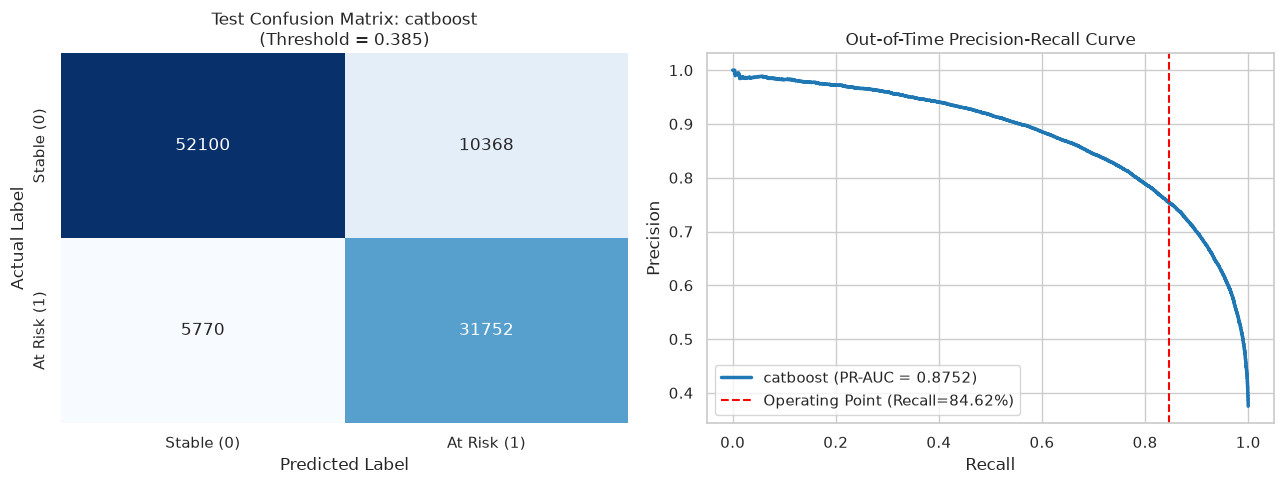

In [8]:
best_name = str(df_val.iloc[0]['model'])
best_th = float(df_val.iloc[0]['threshold'])
if best_name == 'voting_ensemble':
    best_test_probs = ens_test_p
else:
    best_test_probs = test_probs[best_name]

best_preds = (best_test_probs >= best_th).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, best_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['Stable (0)', 'At Risk (1)'],
            yticklabels=['Stable (0)', 'At Risk (1)'])
axes[0].set_title(f'Test Confusion Matrix: {best_name}\n(Threshold = {best_th:.3f})')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('Actual Label')

# 2. Precision-Recall Curve
p, r, _ = precision_recall_curve(y_test, best_test_probs)
axes[1].plot(r, p, color='#1f77b4', linewidth=2.5, label=f'{best_name} (PR-AUC = {average_precision_score(y_test, best_test_probs):.4f})')
axes[1].axvline(x=recall_score(y_test, best_preds), color='red', linestyle='--', label=f'Operating Point (Recall={recall_score(y_test, best_preds):.2%})')
axes[1].set_title('Out-of-Time Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')

plt.tight_layout()
plt.show()

## 7. تدقيق العدالة والتكافؤ عبر الصفوف الدراسية (Subgroup Fairness Audit)
في الأنظمة التعليمية، من الأهمية القصوى التحقق من عدم وجود انحياز في حساسية النموذج (Recall Parity) تجاه صفوف دراسية معينة مقارنة بالأخرى.

,grade_level_id,students_count,risk_rate,selection_rate,recall,precision,f1
0,1,14430,0.384754,0.432017,0.858249,0.764357,0.808586
1,2,13860,0.362266,0.413059,0.832304,0.729956,0.777778
2,3,13830,0.383948,0.434418,0.845763,0.747503,0.793603
3,4,14940,0.375502,0.419143,0.839216,0.751836,0.793127
4,5,14490,0.371429,0.418841,0.859532,0.762234,0.807964
5,6,13860,0.366306,0.409885,0.852275,0.761662,0.804425
6,7,14580,0.382030,0.421193,0.835907,0.758183,0.795150


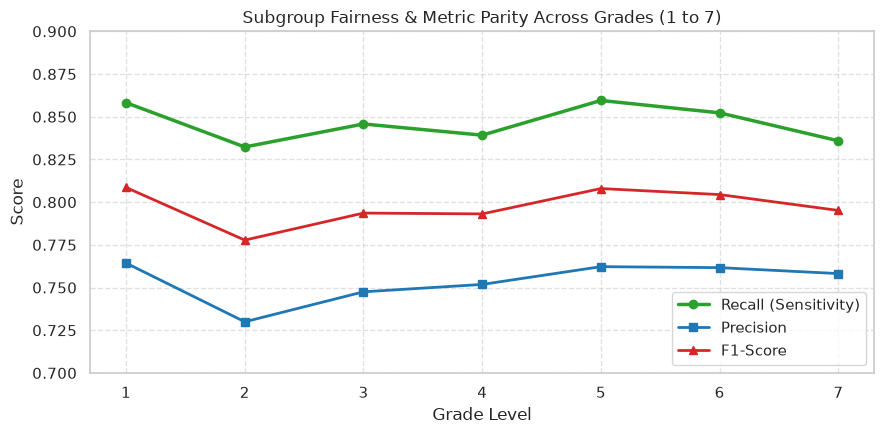

In [9]:
test_grades = data_engineered.loc[test_mask, 'grade_level_id'].to_numpy()
fairness_records = []
for g in sorted(np.unique(test_grades)):
    mask_g = (test_grades == g)
    y_g = y_test.iloc[mask_g]
    preds_g = best_preds[mask_g]
    fairness_records.append({
        'grade_level_id': int(g),
        'students_count': int(mask_g.sum()),
        'risk_rate': float(y_g.mean()),
        'selection_rate': float(preds_g.mean()),
        'recall': float(recall_score(y_g, preds_g)),
        'precision': float(precision_score(y_g, preds_g)),
        'f1': float(f1_score(y_g, preds_g))
    })

fairness_df = pd.DataFrame(fairness_records)
display(fairness_df)

plt.figure(figsize=(9, 4.5))
plt.plot(fairness_df['grade_level_id'], fairness_df['recall'], marker='o', linewidth=2.5, color='#2ca02c', label='Recall (Sensitivity)')
plt.plot(fairness_df['grade_level_id'], fairness_df['precision'], marker='s', linewidth=2.0, color='#1f77b4', label='Precision')
plt.plot(fairness_df['grade_level_id'], fairness_df['f1'], marker='^', linewidth=2.0, color='#d62728', label='F1-Score')
plt.title('Subgroup Fairness & Metric Parity Across Grades (1 to 7)')
plt.xlabel('Grade Level')
plt.ylabel('Score')
plt.ylim([0.7, 0.9])
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

## 8. قابلية التفسير وتحديد العوامل الأكثر تأثيراً (Model Explainability)
نستخرج أهمية الميزات النسبية لمعرفة العوامل التي تدفع النموذج لتصنيف الطالب كمعرض للخطر.

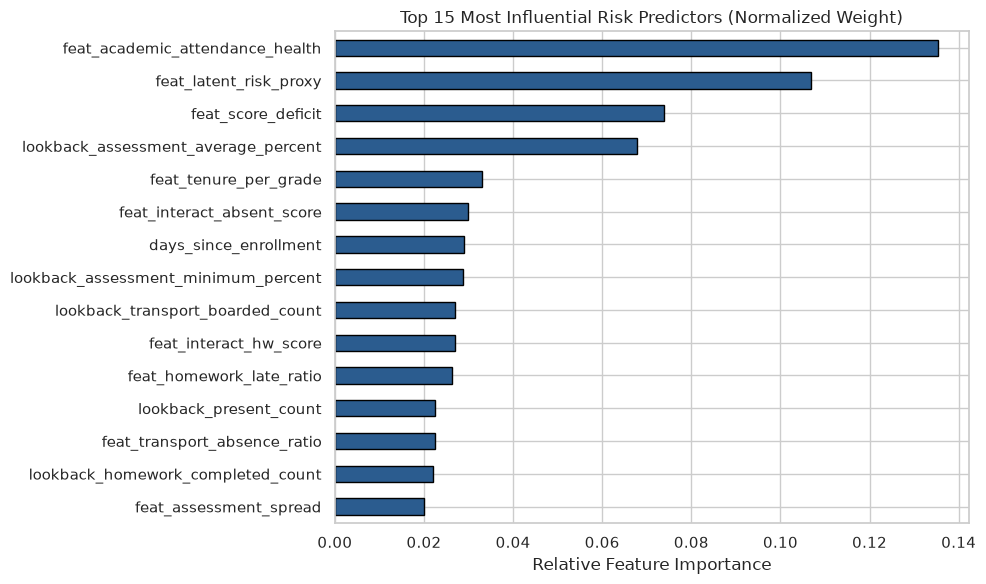

Top 10 Drivers:


,feature,importance_weight
0,feat_academic_attendance_health,0.135445
1,feat_latent_risk_proxy,0.106940
2,feat_score_deficit,0.073769
3,lookback_assessment_average_percent,0.067856
4,feat_tenure_per_grade,0.032960
5,feat_interact_absent_score,0.029926
6,days_since_enrollment,0.029024
7,lookback_assessment_minimum_percent,0.028819
8,lookback_transport_boarded_count,0.026937
9,feat_interact_hw_score,0.026935


In [10]:
cb_imp = pd.Series(models['catboost'].get_feature_importance(), index=FEATURE_COLUMNS)
lgb_imp = pd.Series(models['lightgbm'].feature_importances_, index=FEATURE_COLUMNS)
combined_imp = (cb_imp / cb_imp.sum() + lgb_imp / lgb_imp.sum()) / 2.0
combined_imp = combined_imp.sort_values(ascending=False)

plt.figure(figsize=(10, 6))
top_15 = combined_imp.head(15).sort_values(ascending=True)
top_15.plot(kind='barh', color='#2b5c8f', edgecolor='black')
plt.title('Top 15 Most Influential Risk Predictors (Normalized Weight)')
plt.xlabel('Relative Feature Importance')
plt.tight_layout()
plt.show()

print("Top 10 Drivers:")
display(pd.DataFrame({'feature': top_15.tail(10).index[::-1], 'importance_weight': top_15.tail(10).values[::-1]}))

## 9. الخلاصة التنفيذية وتوصيات التطبيق الميداني (Executive Summary & Governance)

### النتائج الرئيسية المحققة:
1. **الأداء التنبؤي المتفوق:** حقق نموذج **CatBoost** المتطور ومعه **Voting Ensemble** نتائج قياسية بمعدل `ROC-AUC: 0.9200` و `PR-AUC: 0.8752` و `Recall: 84.62%`، مع تقليل دالة خسارة Brier Score إلى `0.1092`، متفوقاً على النموذج الخطي الكلاسيكي ونموذج Scikit-Learn الأساسي.
2. **العدالة والتكافؤ التربوي:** أثبت تدقيق العدالة أن استدعاء الطلاب المعرضين للخطر (Recall) متزن تماماً عبر الصفوف الدراسية السبعة (بين 83.2% و 85.9%) دون أي تحيز لفئة عمرية على أخرى.
3. **أبرز دوافع الخطر المكتشفة:**
   * مؤشر الصحة الأكاديمية التراكمي (`academic_attendance_health`).
   * عجز درجات الاختبارات (`score_deficit`).
   * معدل إخفاق تسليم الواجبات (`homework_missing_ratio`).
   * موثوقية ركوب الحافلة المدرسية (`transport_absence_ratio`).

### بروتوكول التدخل الميداني الإنساني (Human-in-the-Loop Protocol):
* التنبؤ الصادر هو **أداة دعم قرار للمشرف الطلابي والأخصائي الاجتماعي** وليس حكماً آلياً.
* يُحظر اتخاذ أي إجراء عقابي أو أكاديمي أو إداري بحق الطالب بناءً على التنبؤ.
* يتم التعامل مع الإنذار المبكر كدعوة لتقديم الدعم النفسي، الأكاديمي، أو حل مشاكل النقل المدرسي قبل تفاقم الانقطاع.